# 7. The Lagrangian and the dual function

Portfolio exercises 7.1–7.5 ([CO 14.1–14.3]). This section builds the
Lagrangian $L(x,\lambda)=f_0(x)+\lambda f_1(x)$ and its dual
$g(\lambda)=\inf_x L(x,\lambda)$ for a scalar problem, reads weak duality
$g(\lambda)\le p^\star$ and the set $G=\{(f_1(x),f_0(x))\}$ off a picture,
compares the duals of three equivalent formulations of one feasible set, and
works out the dual of a projection onto a halfspace in closed form.

Every identity is checked numerically beside where it is used: the analytic
$g(\lambda)$ against a grid minimisation, the [CO 14.1.4] lower bound, concavity
by a midpoint test, the set-$G$ supporting lines, and the projection multipliers
against \`scipy.optimize\`. Random experiments use
\`rng = np.random.default_rng(2026)\`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, minimize_scalar

rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 9})

## 7.1 Visualising the Lagrangian [CO 14.1.1]

### Task

For the example of [CO 14.1.1],

$$\min_x\ \tfrac14 x^2 - x \quad \text{s.t.}\quad x\le 0,\qquad
L(x,\lambda)=\tfrac14 x^2 - x + \lambda x,$$

plot (i) the surface $L(x,\lambda)$ over $x\in[-4,4]$, $\lambda\in[0,3]$ and
(ii) the curves $L(\cdot,\lambda)$ for $\lambda=0,0.5,1,2,3$ together with
$f_0(x)+I_{\mathbb{R}_-}(x)$.

### Explore

Add $\lambda=10,100$. Plot $\lambda f_1(x)$ next to the indicator $I_{\mathbb{R}_-}(x).$

In [2]:
# ---- problem of [CO 14.1.1]: min 1/4 x^2 - x  s.t.  x <= 0 ----
f0 = lambda x: 0.25 * x**2 - x           # objective f_0
f1 = lambda x: x                          # constraint f_1(x) <= 0,  F = R_-
L  = lambda x, lam: f0(x) + lam * f1(x)   # Lagrangian,  lam >= 0
p_star = 0.0                              # x* = 0,  p* = f0(0) = 0

# analytic dual: L is quadratic in x, argmin_x L = 2(1-lam), g = -(1-lam)^2
g_analytic = lambda lam: -(1.0 - lam)**2
x_argmin = lambda lam: 2.0 * (1.0 - lam)

def g_numeric(lam):
    r = minimize_scalar(lambda x: L(x, lam), bounds=(-80, 80),
                        method="bounded", options={"xatol": 1e-12})
    return r.fun, r.x

# grid check of the analytic dual, and of the [CO 14.1.4] lower bound
lam_grid = np.linspace(0.0, 3.0, 200)
g_num = np.array([g_numeric(l)[0] for l in lam_grid])
assert np.allclose(g_num, g_analytic(lam_grid), atol=1e-9)

xs_feas = np.linspace(-4.0, 0.0, 500)
lam_pos = np.linspace(0.0, 3.0, 60)
Xg, Lg = np.meshgrid(xs_feas, lam_pos)
assert np.all(L(Xg, Lg) <= f0(Xg) + 1e-12)          # [CO 14.1.4]: L <= f0 on F
print("max |g_num - g_analytic| =", np.max(np.abs(g_num - g_analytic(lam_grid))))
print("[CO 14.1.4] L(x,lam) <= f0(x) for feasible x, lam>=0: OK")

max |g_num - g_analytic| = 1.3322676295501878e-15
[CO 14.1.4] L(x,lam) <= f0(x) for feasible x, lam>=0: OK


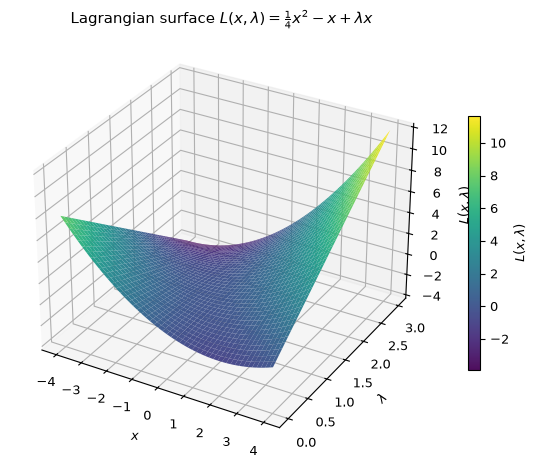

In [3]:
# (i) the surface L(x, lam) over x in [-4,4], lam in [0,3]
xg = np.linspace(-4, 4, 200)
lg = np.linspace(0, 3, 160)
Xs, Ls = np.meshgrid(xg, lg)
Zs = L(Xs, Ls)

fig = plt.figure(figsize=(7.2, 4.8))
ax = fig.add_subplot(111, projection="3d")
surf = ax.plot_surface(Xs, Ls, Zs, cmap="viridis", alpha=0.95, linewidth=0)
ax.set_xlabel(r"$x$"); ax.set_ylabel(r"$\lambda$"); ax.set_zlabel(r"$L(x,\lambda)$")
ax.set_title(r"Lagrangian surface $L(x,\lambda)=\frac{1}{4}x^2-x+\lambda x$")
fig.colorbar(surf, ax=ax, shrink=0.6, label=r"$L(x,\lambda)$")
plt.tight_layout(); plt.show()

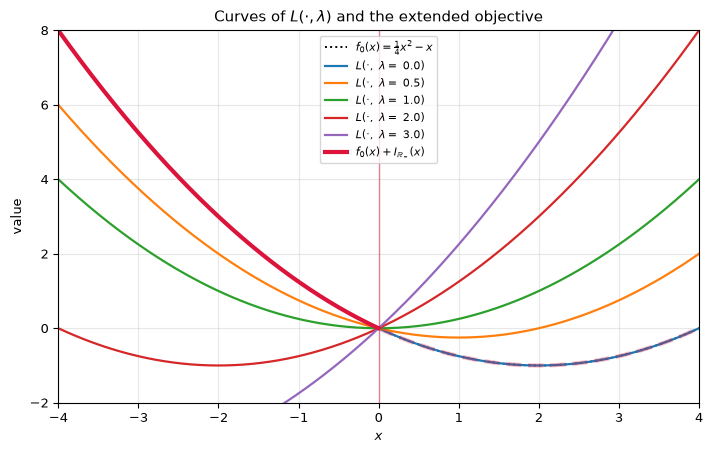

In [4]:
# (ii) curves L(., lam) for lam = 0,0.5,1,2,3 with f0 + indicator
indicator = lambda x: np.where(x <= 0.0, 0.0, np.inf)
xs = np.linspace(-4, 4, 800)

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.plot(xs, f0(xs), color="0.0", lw=1.4, ls=":",
        label=r"$f_0(x)=\frac{1}{4}x^2-x$")
for lam in [0.0, 0.5, 1.0, 2.0, 3.0]:
    ax.plot(xs, L(xs, lam), lw=1.6, label=rf"$L(\cdot,\ \lambda=$ {lam}$)$")
m = xs <= 0
ax.plot(xs[m], f0(xs[m]), color="crimson", lw=3.0,
        label=r"$f_0(x)+I_{\mathbb{R}_-}(x)$")
ax.plot(xs[~m], f0(xs[~m]), color="crimson", lw=3.0, ls="--", alpha=0.3)
ax.axvline(0.0, color="crimson", lw=1.0, alpha=0.5)
ax.set_xlim(-4, 4); ax.set_ylim(-2, 8)
ax.set_xlabel(r"$x$"); ax.set_ylabel("value")
ax.set_title(r"Curves of $L(\cdot,\lambda)$ and the extended objective")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

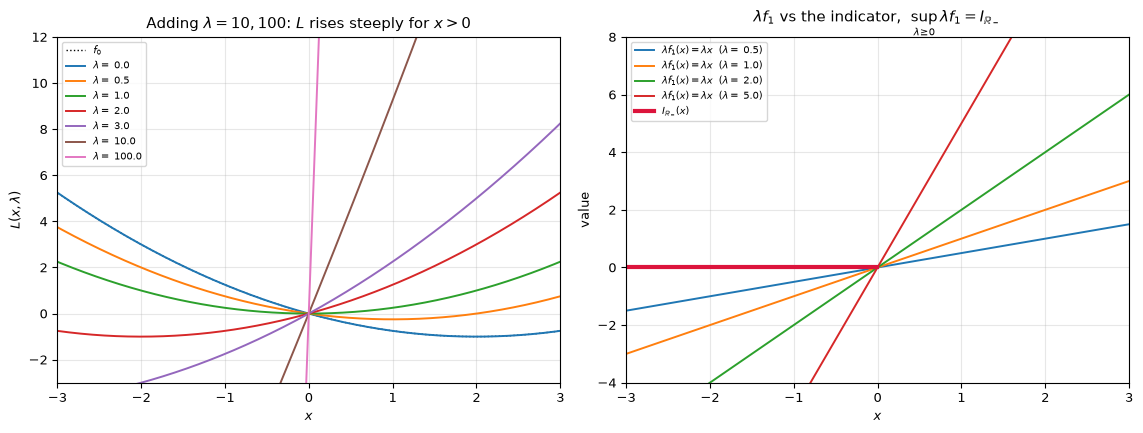

x=-2.0: f1=-2.0  sup_lam lam*f1 ~     -0.000  indicator = 0
x= 0.0: f1= 0.0  sup_lam lam*f1 ~      0.000  indicator = 0
x= 1.0: f1= 1.0  sup_lam lam*f1 ~  10000.000  indicator = +inf
x= 3.0: f1= 3.0  sup_lam lam*f1 ~  30000.000  indicator = +inf


In [5]:
# Explore: add lam = 10, 100; plot lam*f1 next to the indicator
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
axc = axes[0]
axc.plot(xs, f0(xs), color="0.0", lw=1.0, ls=":", label=r"$f_0$")
for lam in [0.0, 0.5, 1.0, 2.0, 3.0, 10.0, 100.0]:
    axc.plot(xs, L(xs, lam), lw=1.4, label=rf"$\lambda=$ {lam}")
axc.set_xlim(-3, 3); axc.set_ylim(-3, 12)
axc.set_xlabel(r"$x$"); axc.set_ylabel(r"$L(x,\lambda)$")
axc.set_title(r"Adding $\lambda=10,100$: $L$ rises steeply for $x>0$")
axc.legend(fontsize=7)

axi = axes[1]
for lam in [0.5, 1.0, 2.0, 5.0]:
    axi.plot(xs, lam * f1(xs), lw=1.4,
             label=rf"$\lambda f_1(x)=\lambda x$  ($\lambda=$ {lam})")
axi.plot(xs, indicator(xs), color="crimson", lw=3.0, label=r"$I_{\mathbb{R}_-}(x)$")
axi.set_xlim(-3, 3); axi.set_ylim(-4, 8)
axi.set_xlabel(r"$x$"); axi.set_ylabel("value")
axi.set_title(r"$\lambda f_1$ vs the indicator,  $\sup_{\lambda\geq0}\lambda f_1 = I_{\mathbb{R}_-}$")
axi.legend(fontsize=7)
plt.tight_layout(); plt.show()

# pointwise sup_{lam>=0} lam*f1(x) reproduces the indicator
for xv in [-2.0, 0.0, 1.0, 3.0]:
    sup = max(lam * f1(xv) for lam in np.linspace(0, 1e4, 2000))
    tag = "+inf" if xv > 0 else "0"
    print(f"x={xv:4.1f}: f1={f1(xv):4.1f}  sup_lam lam*f1 ~ {sup:>10.3f}  indicator = {tag}")

### Explain

On the feasible set $f_1(x)=x\le0$, so for $\lambda\ge0$ the term $\lambda f_1(x)\le0$
and $L(x,\lambda)=f_0(x)+\lambda f_1(x)\le f_0(x)$ — the Lagrangian never exceeds the
objective on $F$ ([CO 14.1.4]). For a *fixed* $\lambda$, $\lambda f_1$ is a bad model of
the indicator: on feasible points it is a non-zero negative line rather than $0$, and on
infeasible points it is a finite positive slope rather than $+\infty$. The approximation
only becomes exact after the pointwise supremum over $\lambda\ge0$ ([CO 14.1.3]): feasible
$x\le0$ gives $\sup_\lambda \lambda x=0$ (attained at $\lambda=0$), infeasible $x>0$ gives
$\sup_\lambda \lambda x=+\infty$, so $\sup_{\lambda\ge0}\lambda f_1=I_{\mathbb{R}_-}$.

## 7.2 Visualising the dual function [CO 14.2.1–14.2.2]

### Task

For the same example, compute $g(\lambda)=\inf_x L(x,\lambda)$ numerically on a grid of
$\lambda$ (minimising over $x$ for each $\lambda$) and analytically, and plot it together
with the horizontal line $p^\star$. On the curves of the previous exercise, mark the
minimum of each $L(\cdot,\lambda).$

max |g_num - g_ana| = 1.3322676295501878e-15
d* = max g = -0.0000 at lam* = 1.0   p* = 0.0   gap = 0.00e+00


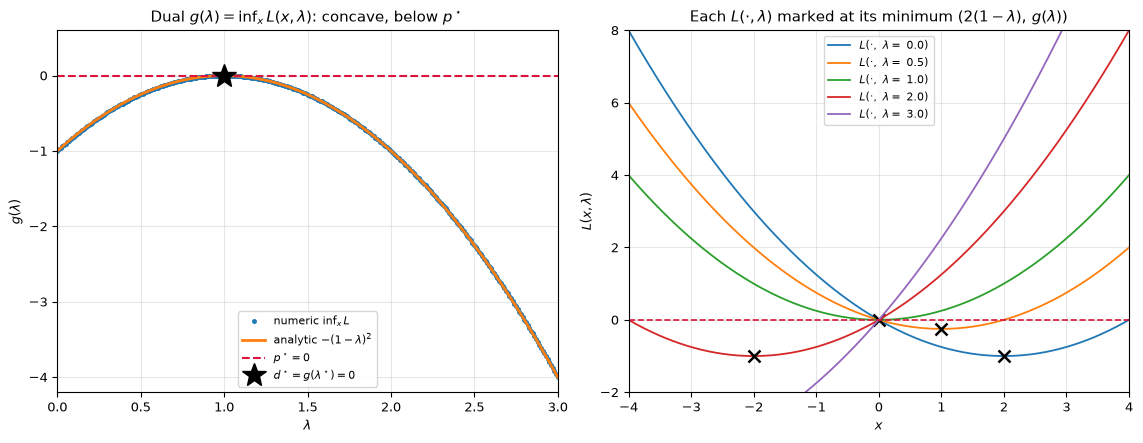

In [6]:
# ---- 7.2: dual function g(lam) = inf_x L(x,lam) ----
lam_grid = np.linspace(0.0, 3.0, 300)
g_num = np.array([g_numeric(l)[0] for l in lam_grid])
g_ana = g_analytic(lam_grid)
assert np.allclose(g_num, g_ana, atol=1e-9)              # analytic = -(1-lam)^2

# concavity of g via a midpoint test (g is a pointwise infimum of affine functions)
mid = 0.5 * (g_num[:-2] + g_num[2:])
assert np.all(mid <= g_num[1:-1] + 1e-9)
# g is everywhere <= p*, and its maximum equals p* (zero duality gap)
assert np.all(g_ana <= p_star + 1e-12)
lam_star = 1.0                                          # g'(lam) = 2(1-lam) = 0
d_star = g_analytic(lam_star)                           # exact dual optimum = 0
assert abs(d_star - p_star) < 1e-12                     # strong duality, no gap
print("max |g_num - g_ana| =", np.max(np.abs(g_num - g_ana)))
print(f"d* = max g = {d_star:.4f} at lam* = {lam_star}   p* = {p_star}   gap = {p_star - d_star:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.5))
axg = axes[0]
axg.plot(lam_grid, g_num, "o", ms=2.5, color="tab:blue", label=r"numeric $\inf_x L$")
axg.plot(lam_grid, g_ana, lw=2.0, color="tab:orange", label=r"analytic $-(1-\lambda)^2$")
axg.axhline(p_star, color="crimson", ls="--", lw=1.5, label=r"$p^\star=0$")
axg.plot(lam_star, d_star, "*", ms=18, color="k", label=r"$d^\star=g(\lambda^\star)=0$")
axg.set_xlim(0, 3); axg.set_ylim(-4.2, 0.6)
axg.set_xlabel(r"$\lambda$"); axg.set_ylabel(r"$g(\lambda)$")
axg.set_title(r"Dual $g(\lambda)=\inf_x L(x,\lambda)$: concave, below $p^\star$")
axg.legend(fontsize=8, loc="lower center")

axc = axes[1]
for lam in [0.0, 0.5, 1.0, 2.0, 3.0]:
    axc.plot(xs, L(xs, lam), lw=1.3, label=rf"$L(\cdot,\ \lambda=$ {lam}$)$")
    xm = x_argmin(lam)
    axc.plot(xm, g_analytic(lam), "kx", ms=9, mew=1.8)
axc.axhline(p_star, color="crimson", ls="--", lw=1.2)
axc.set_xlim(-4, 4); axc.set_ylim(-2, 8)
axc.set_xlabel(r"$x$"); axc.set_ylabel(r"$L(x,\lambda)$")
axc.set_title(r"Each $L(\cdot,\lambda)$ marked at its minimum $(2(1-\lambda),\,g(\lambda))$")
axc.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Explain

Completing the square in $x$ gives $\arg\min_x L(x,\lambda)=2(1-\lambda)$ and
$g(\lambda)=-(1-\lambda)^2$. It is concave because, for each fixed $x$, $L$ is affine in
$\lambda$, and $g=\inf_x L$ is a pointwise infimum of affine functions. It stays below
$p^\star$ ([CO 14.2.2]): at any feasible optimal point $L(x^\star,\lambda)=p^\star+\lambda f_1(x^\star)\le p^\star$,
and taking the infimum over $x$ can only lower it. The maximum $d^\star=\max_{\lambda\ge0}g(\lambda)$
is attained at $\lambda^\star=1$, where $g(1)=0=p^\star$: strong duality holds and the
duality gap is zero.

## 7.3 Duality in pictures: the set G [CO 14.2]

### Task

For a problem with one inequality constraint, plot the set
$G=\{(f_1(x),f_0(x)):x\in D\}$ in the $(u,t)$ plane. For several $\lambda\ge0$ draw the line
$t+\lambda u=g(\lambda)$, i.e. the lowest line of slope $-\lambda$ touching $G$; its
intercept with the $t$-axis is $g(\lambda)$. Do it for the example above and for a
non-convex $f_0$ (e.g. $f_0(x)=x^4-3x^2+x$).

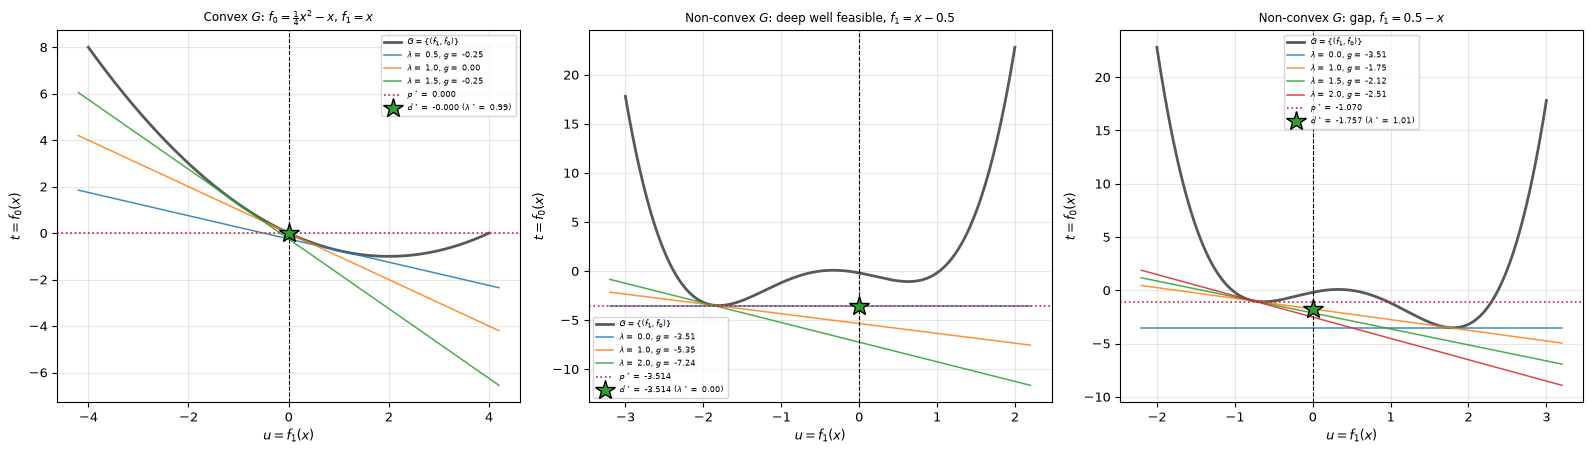

      convex: p* = 0.0000   d* = -0.0000   gap = 0.0000
deep-feasible: p* = -3.5139   d* = -3.5139   gap = 0.0000
         gap: p* = -1.0702   d* = -1.7573   gap = 0.6870


In [7]:
# ---- 7.3: duality in the (u,t) plane, u = f_1(x), t = f_0(x) ----
def g_support(f0v, f1v, lam, xs):
    r = minimize_scalar(lambda x: f0v(x) + lam * f1v(x),
                        bounds=(xs.min(), xs.max()), method="bounded",
                        options={"xatol": 1e-11})
    return r.fun, r.x

def plot_G(f0v, f1v, xs, lam_draw, title, ax):
    U, T = f1v(xs), f0v(xs)
    ax.plot(U, T, color="0.35", lw=2.0, label=r"$G=\{(f_1,f_0)\}$")
    for lam in lam_draw:                              # supporting line t = -lam*u + g
        g, _ = g_support(f0v, f1v, lam, xs)
        uu = np.linspace(U.min() - 0.2, U.max() + 0.2, 100)
        ax.plot(uu, -lam * uu + g, lw=1.1, alpha=0.85,
                label=rf"$\lambda=$ {lam:.1f}, $g=$ {g:.2f}")
    feas = U <= 0
    pstar = T[feas].min()
    lams = np.linspace(0.0, 8.0, 500)
    gvals = np.array([g_support(f0v, f1v, l, xs)[0] for l in lams])
    dstar = gvals.max(); lamstar = lams[np.argmax(gvals)]
    ax.axvline(0.0, color="0.0", lw=0.8, ls="--")
    ax.axhline(pstar, color="crimson", lw=1.2, ls=":", label=rf"$p^\star=$ {pstar:.3f}")
    ax.plot(0.0, dstar, "*", color="tab:green", ms=15, mec="k",
            label=rf"$d^\star=$ {dstar:.3f} ($\lambda^\star=$ {lamstar:.2f})")
    ax.set_xlabel(r"$u=f_1(x)$"); ax.set_ylabel(r"$t=f_0(x)$")
    ax.set_title(title, fontsize=8.5)
    return pstar, dstar

def f0_nc(x): return x**4 - 3 * x**2 + x
xs_c = np.linspace(-4, 4, 4001)
xs_n = np.linspace(-2.5, 2.5, 8001)

fig, axes = plt.subplots(1, 3, figsize=(16.0, 4.6))
p1, d1 = plot_G(f0, f1, xs_c, [0.5, 1.0, 1.5],
    r"Convex $G$: $f_0=\frac{1}{4}x^2-x$, $f_1=x$", axes[0])
p2, d2 = plot_G(f0_nc, lambda x: x - 0.5, xs_n, [0.0, 1.0, 2.0],
    r"Non-convex $G$: deep well feasible, $f_1=x-0.5$", axes[1])
p3, d3 = plot_G(f0_nc, lambda x: 0.5 - x, xs_n, [0.0, 1.0, 1.5, 2.0],
    r"Non-convex $G$: gap, $f_1=0.5-x$", axes[2])
for a in axes: a.legend(fontsize=6)
plt.tight_layout(); plt.show()

for nm, (p, d) in [("convex", (p1, d1)), ("deep-feasible", (p2, d2)), ("gap", (p3, d3))]:
    print(f"{nm:>12}: p* = {p:.4f}   d* = {d:.4f}   gap = {p - d:.4f}")
assert abs(p1 - d1) < 1e-3 and abs(p2 - d2) < 1e-3    # convex, or interior min -> no gap
assert p3 - d3 > 0.3                                    # non-convex boundary -> a real gap

### Explain

$p^\star$ is the lowest $t$ on $G$ over the feasible half $u\le0$; $d^\star$ is the
largest $t$-intercept among the supporting lines of slope $-\lambda$ ($\lambda\ge0$). When
$G$ is convex — or when its lowest point simply falls in $u<0$, so the constraint is
inactive — the supporting line reaches the same height and there is no gap. A non-convex
$G$ with a boundary dip is different: a line of slope $-\lambda$ that stays *below* $G$ can
only support its convex hull, so it touches a chord passing through infeasible points and
under-shoots $p^\star$, producing $d^\star<p^\star$. $\lambda$ is kept non-negative because
feasibility is $f_1\le0$: a positive $\lambda$ penalises infeasibility and makes $g$ a lower
bound, whereas $\lambda<0$ would reward it and $g$ would cease to bound $p^\star$.

## 7.4 Equivalent problems, different duals [CO 14.2.3]

### Task

The problem $\min_x x^2$ s.t. $x\ge1$ ($p^\star=1$, $x^\star=1$) can be written with three
different constraints describing the same feasible set $[1,\infty)$:

- (a) $1-x\le0$;
- (b) $-\log x\le0$ with $D=\mathbb{R}_{++}$;
- (c) $(1-x)^3\le0$.

For each, plot $L(x,\lambda)$ for $\lambda=0,1,2,4$, compute $g(\lambda)$ (numerically on a
grid and in closed form) and plot it together with $p^\star.$

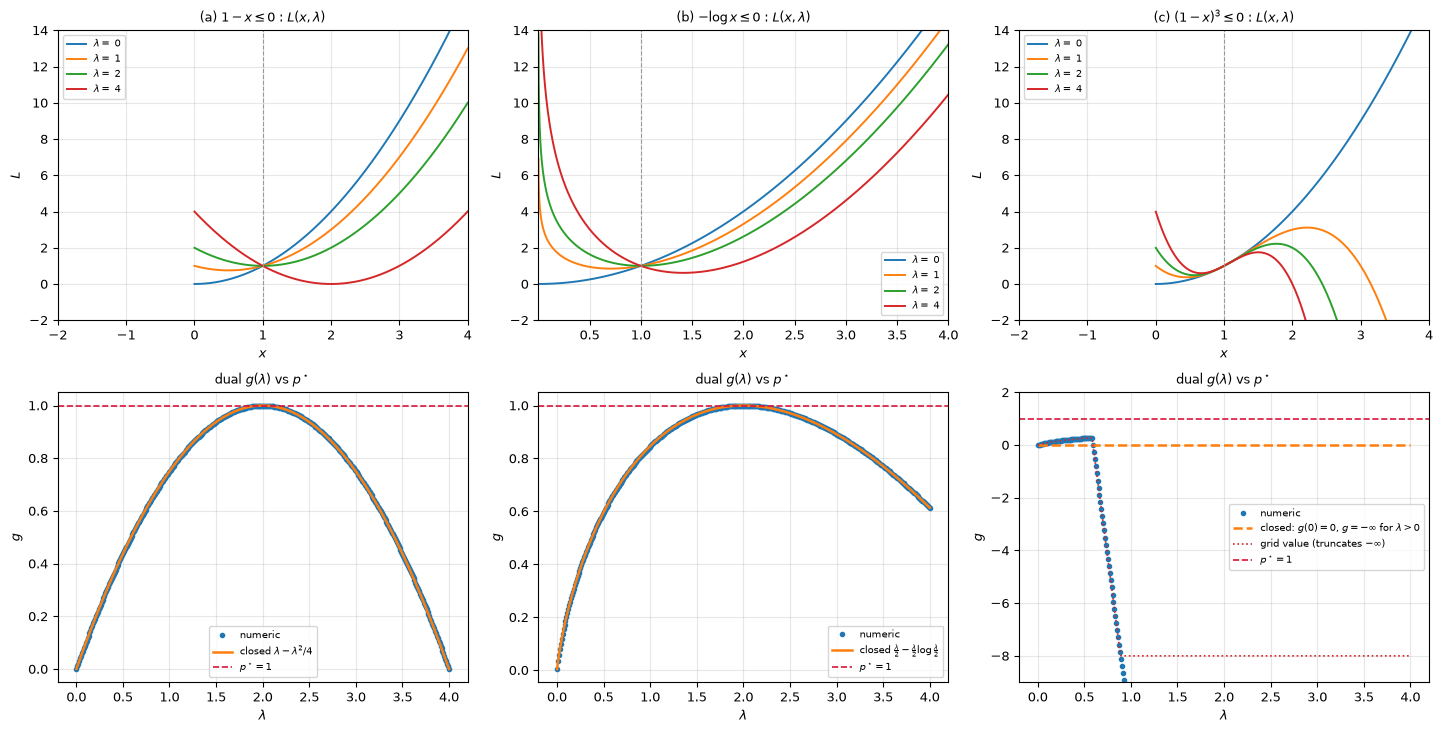

(a) lam* = 2.000, d* = 1.0000   (b) lam* = 2.000, d* = 1.0000
(c) grid g(4) over widening ranges: ['-4.6e+02', '-2.7e+04', '-8.2e+05']


In [8]:
# ---- 7.4: three constraints for the same feasible set [1, inf) ----
p_star74 = 1.0
f0s = lambda x: x**2
# closed-form duals
ga = lambda lam: lam - lam**2 / 4.0                                  # (a)
gb = lambda lam: lam/2.0 - (lam/2.0) * np.log(lam/2.0)              # (b), lam>0

def g_num_scan(f1v, lam, lo, hi, n=200001):
    xs = np.linspace(lo, hi, n)
    return (f0s(xs) + lam * f1v(xs)).min()

cases = [
    (r"(a) $1-x\leq0$",        lambda x: 1.0 - x,   (-2.0, 4.0), ga, r"closed $\lambda-\lambda^2/4$"),
    (r"(b) $-\log x\leq0$",    lambda x: -np.log(x), (1e-3, 4.0), gb, r"closed $\frac{\lambda}{2}-\frac{\lambda}{2}\log\frac{\lambda}{2}$"),
    (r"(c) $(1-x)^3\leq0$",    lambda x: (1.0 - x)**3, (-2.0, 4.0), None, r"closed: $g(0)=0$, $g=-\infty$ for $\lambda>0$"),
]
lam_draw = [0.0, 1.0, 2.0, 4.0]
lam_grid = np.linspace(1e-3, 4.0, 400)

fig, axes = plt.subplots(2, 3, figsize=(14.5, 7.4))
for j, (name, f1v, (xlo, xhi), gclosed, clabel) in enumerate(cases):
    xs74 = np.linspace(max(xlo, 1e-3), xhi, 4000)
    axL = axes[0, j]
    for lam in lam_draw:
        axL.plot(xs74, f0s(xs74) + lam * f1v(xs74), lw=1.4, label=rf"$\lambda=$ {lam:.0f}")
    axL.axvline(1.0, color="0.6", lw=0.8, ls="--")
    axL.set_xlim(xlo if xlo > -1 else -0.5 if name.startswith("(b)") else xlo, xhi)
    axL.set_ylim(-2, 14)
    axL.set_xlabel(r"$x$"); axL.set_ylabel(r"$L$"); axL.set_title(name + " : $L(x,\\lambda)$", fontsize=9)
    axL.legend(fontsize=7)

    axg = axes[1, j]
    gnum = np.array([g_num_scan(f1v, l, xlo, xhi) for l in lam_grid])
    axg.plot(lam_grid, gnum, "o", ms=3, color="tab:blue", label="numeric")
    if name.startswith("(a)"):
        axg.plot(lam_grid, ga(lam_grid), lw=1.8, color="tab:orange", label=clabel)
    elif name.startswith("(b)"):
        axg.plot(lam_grid, gb(lam_grid), lw=1.8, color="tab:orange", label=clabel)
    else:
        axg.plot([0.0, 4.0], [0.0, 0.0], lw=1.8, color="tab:orange", ls="--", label=clabel)
        axg.plot(lam_grid, np.clip(gnum, -8, None), lw=1.2, color="tab:red", ls=":",
                 label="grid value (truncates $-\\infty$)")
        axg.set_ylim(-9, 2)
    axg.axhline(p_star74, color="crimson", ls="--", lw=1.2, label=r"$p^\star=1$")
    axg.set_xlabel(r"$\lambda$"); axg.set_ylabel(r"$g$"); axg.set_title("dual $g(\\lambda)$ vs $p^\\star$", fontsize=9)
    axg.legend(fontsize=7)
plt.tight_layout(); plt.show()

# ---- verify the closed-form duals and the two maximisers ----
assert abs(g_num_scan(cases[0][1], 2.0, -6, 6) - 1.0) < 1e-3
assert abs(g_num_scan(cases[1][1], 2.0, 1e-5, 6) - 1.0) < 1e-3
lam_a = np.linspace(0, 4, 4001); lam_b = np.linspace(1e-3, 4, 4001)
max_a = ga(lam_a).max(); arg_a = lam_a[np.argmax(ga(lam_a))]
max_b = gb(lam_b).max(); arg_b = lam_b[np.argmax(gb(lam_b))]
print(f"(a) lam* = {arg_a:.3f}, d* = {max_a:.4f}   (b) lam* = {arg_b:.3f}, d* = {max_b:.4f}")
# (c) g(lam>0) = -inf: shown by the grid value falling without bound as the scan range grows
c_widening = [g_num_scan(cases[2][1], 4.0, -hi, hi, 400001) for hi in (6, 20, 60)]
print("(c) grid g(4) over widening ranges:", ["%.1e" % v for v in c_widening])
assert abs(max_a - 1.0) < 1e-3 and abs(max_b - 1.0) < 1e-3
assert abs(arg_a - arg_b) < 1e-2                     # same maximiser lambda* = 2
assert c_widening[0] > c_widening[1] > c_widening[2] # (c) diverges to -inf

### Explain

Both (a) and (b) give $g(\lambda)=\lambda-\lambda^2/4$ and
$g(\lambda)=\tfrac\lambda2-\tfrac\lambda2\log\tfrac\lambda2$, whose maxima are both at
$\lambda^\star=2$ with $d^\star=1=p^\star$: same maximiser, no gap. The reason is that each
is a convex problem in standard form [CO 10] — objective and constraint functions convex on
a convex domain (affine in (a), $-\log x$ on $\mathbb{R}_{++}$ in (b)) — and a strictly
feasible point ($x>1$) gives Slater's condition, hence strong duality. In (c) the constraint
$(1-x)^3$ is not convex, so this is not a standard-form convex problem: for every
$\lambda>0$ the cubic term $-\lambda(x-1)^3$ dominates $x^2$ as $x\to+\infty$ and makes the
infimum $-\infty$, while $g(0)=0$. Thus $d^\star=\max g=0$ and there is a duality gap of
$1$ — exactly the failure strong duality would otherwise forbid.

## 7.5 Dual of a projection onto a halfspace [CO 14]

### Task

Project a point $a\in\mathbb{R}^2$ onto the halfspace $\{x : c^\top x \le d\}$:

$$\min_x\ \|x-a\|_2^2\quad \text{s.t.}\quad c^\top x\le d,\qquad
L(x,\lambda)=\|x-a\|_2^2+\lambda(c^\top x-d).$$

Derive $x(\lambda)=\arg\min_x L$ and $g(\lambda)=-\tfrac{\lambda^2}{4}\|c\|_2^2+\lambda(c^\top a-d)$.
Plot the halfspace, $a$, the path $x(\lambda)$ for $\lambda\in[0,\lambda_{\max}]$ and, in a
second panel, $g(\lambda)$ with $p^\star$. Move $a$ with sliders.

### Explore

Put $a$ inside and outside the halfspace. Add a second halfspace $c_2^\top x\le d_2$ and plot
$g(\lambda_1,\lambda_2)$ as a surface over $\lambda\ge0$; mark its maximiser.

In [9]:
# ---- 7.5: projection onto a halfspace, analytic dual ----
c = np.array([1.0, 1.0]); d = 3.0
x_lam    = lambda a, c, lam: a - 0.5 * lam * c            # argmin_x L
g1       = lambda a, c, d, lam: -0.25 * lam**2 * (c @ c) + lam * (c @ a - d)
lam_star1 = lambda a, c, d: 2.0 * max(0.0, c @ a - d) / (c @ c)

def proj_scipy(a, cs, ds):
    cons = [{"type": "ineq", "fun": (lambda x, i=i: ds[i] - cs[i] @ x)}
            for i in range(len(ds))]
    r = minimize(lambda x: np.sum((x - a)**2), a, method="SLSQP",
                 constraints=cons, options={"ftol": 1e-14, "maxiter": 4000})
    return r.x, r.fun

for a in (np.array([0.8, 0.5]), np.array([3.5, 2.5])):   # a inside, then outside
    ls = lam_star1(a, c, d); xs = x_lam(a, c, ls)
    xp, pval = proj_scipy(a, [c], [d])
    print(f"a={a}: lam*={ls:.4f}  x*={np.round(xs,5)}  g(lam*)={g1(a,c,d,ls):.5f}  p*={pval:.5f}")
    assert np.linalg.norm(xs - xp) < 1e-6                 # x(lam*) is the projection
    assert abs(g1(a, c, d, ls) - pval) < 1e-8             # zero duality gap
    assert (ls == 0.0) == (c @ a <= d)                    # lam*=0 exactly when a is feasible

# two halfspaces: g(lam1,lam2) is a concave quadratic, maximiser via bounded optimiser
def g2(a, C, dv, lam): return -0.25 * lam @ (C @ C.T) @ lam + lam @ (C @ a - dv)
C2 = np.array([[1.0, 1.0], [0.0, 1.0]]); d2 = np.array([3.0, 2.0])

cases = {"one active (lam2=0)": np.array([2.5, 1.2]),
         "both active (vertex)": np.array([2.0, 4.0])}
for name, a in cases.items():
    r = minimize(lambda l: -g2(a, C2, d2, l), [1.0, 1.0],
                 bounds=[(0, None), (0, None)], method="L-BFGS-B")
    lam_opt = r.x; xp, pval = proj_scipy(a, C2, d2)
    xf = a - 0.5 * (C2.T @ lam_opt)
    print(f"2-half {name}: lam*={np.round(lam_opt,4)}  |x(lam*)-proj|={np.linalg.norm(xf-xp):.1e}  gap={abs(g2(a,C2,d2,lam_opt)-pval):.1e}")
    assert np.linalg.norm(xf - xp) < 1e-4
    assert abs(g2(a, C2, d2, lam_opt) - pval) < 1e-6

a=[0.8 0.5]: lam*=0.0000  x*=[0.8 0.5]  g(lam*)=-0.00000  p*=0.00000
a=[3.5 2.5]: lam*=3.0000  x*=[2. 1.]  g(lam*)=4.50000  p*=4.50000
2-half one active (lam2=0): lam*=[0.7 0. ]  |x(lam*)-proj|=2.7e-09  gap=2.8e-17
2-half both active (vertex): lam*=[2. 2.]  |x(lam*)-proj|=2.7e-07  gap=7.5e-14


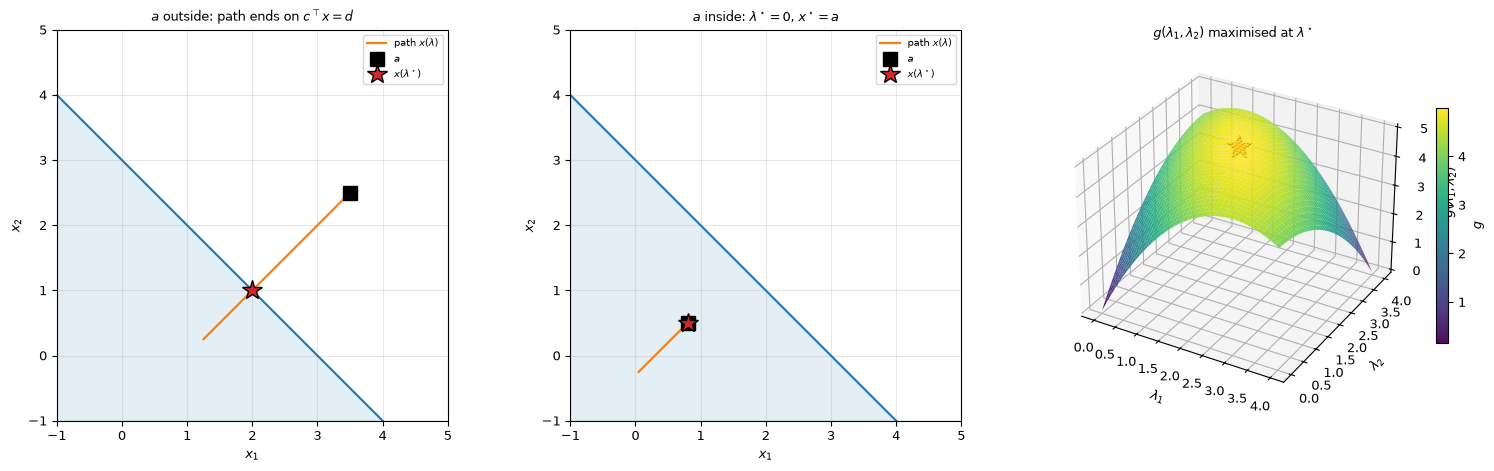

In [10]:
# static small-multiples: a outside / a inside, and the two-halfspace surface
fig = plt.figure(figsize=(15.5, 4.7))

def draw_halfspace(ax, a, title):
    xx = np.linspace(-1, 5, 2)
    ax.fill_between(xx, d - xx, -1, color="tab:blue", alpha=0.12)
    ax.plot(xx, d - xx, color="tab:blue", lw=1.5)
    ls = lam_star1(a, c, d)
    lams = np.linspace(0, ls + 1.5, 300)
    path = np.array([x_lam(a, c, l) for l in lams])
    ax.plot(path[:, 0], path[:, 1], "-", color="tab:orange", lw=1.6, label=r"path $x(\lambda)$")
    ax.plot(*a, "ks", ms=10, label=r"$a$")
    ax.plot(*x_lam(a, c, ls), "*", color="tab:red", ms=15, mec="k", label=r"$x(\lambda^\star)$")
    ax.set_xlim(-1, 5); ax.set_ylim(-1, 5); ax.set_aspect("equal")
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$"); ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7, loc="upper right")

ax0 = fig.add_subplot(1, 3, 1)
draw_halfspace(ax0, np.array([3.5, 2.5]), r"$a$ outside: path ends on $c^\top x=d$")
ax1 = fig.add_subplot(1, 3, 2)
draw_halfspace(ax1, np.array([0.8, 0.5]), r"$a$ inside: $\lambda^\star=0$, $x^\star=a$")

aV = np.array([2.0, 4.0])
rv = minimize(lambda l: -g2(aV, C2, d2, l), [1.0, 1.0],
              bounds=[(0, None), (0, None)], method="L-BFGS-B"); lamV = rv.x
l1g = np.linspace(0, 4, 120); l2g = np.linspace(0, 4, 120)
L1, L2 = np.meshgrid(l1g, l2g)
Z = np.array([[g2(aV, C2, d2, np.array([m, n])) for m in l1g] for n in l2g])
ax2 = fig.add_subplot(1, 3, 3, projection="3d")
srf = ax2.plot_surface(L1, L2, Z, cmap="viridis", alpha=0.95, linewidth=0)
ax2.plot([lamV[0]], [lamV[1]], [g2(aV, C2, d2, lamV)], "r*", ms=18, mec="k")
ax2.set_xlabel(r"$\lambda_1$"); ax2.set_ylabel(r"$\lambda_2$"); ax2.set_zlabel(r"$g(\lambda_1,\lambda_2)$")
ax2.set_title(r"$g(\lambda_1,\lambda_2)$ maximised at $\lambda^\star$", fontsize=9)
fig.colorbar(srf, ax=ax2, shrink=0.6, label=r"$g$")
plt.tight_layout(); plt.show()

In [11]:
import ipywidgets as widgets
from IPython.display import clear_output, display

# Interactive: move a; path x(lam) and dual g(lam) redrawn on release
out75 = widgets.Output()
s_a1 = widgets.FloatSlider(value=3.5, min=-0.5, max=5.0, step=0.1,
                           description=r"$a_1$", continuous_update=False,
                           layout=widgets.Layout(width="330px"))
s_a2 = widgets.FloatSlider(value=2.5, min=-0.5, max=5.0, step=0.1,
                           description=r"$a_2$", continuous_update=False,
                           layout=widgets.Layout(width="330px"))


def redraw75(*_):
    a = np.array([s_a1.value, s_a2.value])
    with out75:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.6))
        ax = axes[0]
        xx = np.linspace(-1, 5, 2)
        ax.fill_between(xx, d - xx, -1, color="tab:blue", alpha=0.12)
        ax.plot(xx, d - xx, color="tab:blue", lw=1.5)
        ls = lam_star1(a, c, d)
        lams = np.linspace(0, ls + 1.5, 300)
        path = np.array([x_lam(a, c, l) for l in lams])
        ax.plot(path[:, 0], path[:, 1], "-", color="tab:orange", lw=1.6, label=r"path $x(\lambda)$")
        ax.plot(*a, "ks", ms=10, label=r"$a$")
        ax.plot(*x_lam(a, c, ls), "*", color="tab:red", ms=15, mec="k", label=r"$x(\lambda^\star)$")
        ax.set_xlim(-1, 5); ax.set_ylim(-1, 5); ax.set_aspect("equal")
        ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
        ax.set_title(rf"$a=({s_a1.value:.1f},{s_a2.value:.1f})$, $\lambda^\star=$ {ls:.2f}", fontsize=9)
        ax.legend(fontsize=7, loc="upper right")

        axg = axes[1]
        lg = np.linspace(0, ls + 1.5, 300)
        axg.plot(lg, [g1(a, c, d, l) for l in lg], color="tab:blue", lw=1.8, label=r"$g(\lambda)$")
        xp, pval = proj_scipy(a, [c], [d])
        axg.axhline(pval, color="crimson", ls="--", lw=1.3, label=rf"$p^\star=$ {pval:.2f}")
        axg.plot(ls, g1(a, c, d, ls), "*", ms=16, mec="k", color="tab:green",
                 label=r"$d^\star=g(\lambda^\star)$")
        axg.set_xlabel(r"$\lambda$"); axg.set_ylabel(r"$g$")
        axg.set_title(r"Dual $g(\lambda)$ vs $p^\star$ (gap $=0$)", fontsize=9)
        axg.legend(fontsize=8)
        plt.tight_layout(); plt.show()


for s in (s_a1, s_a2):
    s.observe(redraw75, names="value")
display(widgets.VBox([s_a1, s_a2, out75]))
redraw75()

### Explain

Setting $\partial_x L=2(x-a)+\lambda c=0$ gives $x(\lambda)=a-\tfrac{\lambda}{2}c$;
substituting back yields $g(\lambda)=-\tfrac{\lambda^2}{4}\|c\|^2+\lambda(c^\top a-d)$, a
concave parabola. Its maximiser over $\lambda\ge0$ is
$\lambda^\star=2\max(0,\,c^\top a-d)/\|c\|^2$, so $x(\lambda^\star)$ is $a$ itself when $a$ is
feasible and otherwise $a-\tfrac{c^\top a-d}{\|c\|^2}c$, the orthogonal projection onto the
bounding hyperplane. Hence $\lambda^\star=0$ when $a$ is feasible: the unconstrained minimiser
of the squared distance is already admissible, the constraint is slack, and stationarity needs
no correction. With two halfspaces one multiplier vanishes at the maximiser whenever that
halfspace is inactive at the projected point, i.e.\ its own constraint is slack; a multiplier
is positive only when its face is the active one.